# Proyecto final · Olist: del pedido a la reseña

**Equipo:**
<br>

|Nombre|Apellido|
|---|---|
|Alexia Carolina|Guevara Mendoza|
|Oscar Yasher|Villalta Yada|
|Javier Alejandro|Andino García|

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores. **Activen la GPU** (Entorno de ejecución › Cambiar tipo de entorno › T4 GPU) para la Parte 4.

## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.

In [1]:
import os
import warnings
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # en Windows 11 loky busca wmic y llena la salida de avisos
HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
CLAVE = os.environ.get("OLIST_CLAVE") or getpass("Contraseña: ")
motor = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(CLAVE)}@{HOST}:5432/postgres", poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato. Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [2]:
query = '''
WITH items AS (                       -- agrega los artículos por pedido
    SELECT order_id,
           COUNT(*)                    AS n_items,
           COUNT(DISTINCT seller_id)   AS n_vendedores,
           SUM(price)                  AS precio_total,
           SUM(freight_value)          AS flete_total
    FROM final.order_items
    GROUP BY order_id
),
peso_fotos AS (                       -- peso y fotos, uniendo con products
    SELECT oi.order_id,
           SUM(p.product_weight_g)     AS peso_total_g,
           AVG(p.product_photos_qty)   AS fotos_promedio
    FROM final.order_items oi
    JOIN final.products p ON p.product_id = oi.product_id
    GROUP BY oi.order_id
),
articulo1 AS (                        -- categoría y estado del vendedor del artículo 1
    SELECT oi.order_id,
           p.product_category_name     AS categoria,
           s.seller_state              AS estado_vendedor
    FROM final.order_items oi
    JOIN final.products p ON p.product_id = oi.product_id
    JOIN final.sellers  s ON s.seller_id  = oi.seller_id
    WHERE oi.order_item_id = 1
),
pago AS (                             -- tipo de pago del de MAYOR monto y cuotas máximas
    SELECT order_id,
           (ARRAY_AGG(payment_type ORDER BY payment_value DESC))[1] AS tipo_pago,
           MAX(payment_installments)   AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
),
resena AS (                           -- una sola reseña por pedido: la más reciente
    SELECT DISTINCT ON (order_id)
           order_id,
           CASE WHEN review_score IN (1, 2) THEN 1 ELSE 0 END AS mala_resena
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC
)
SELECT o.order_id,
       o.order_purchase_timestamp, o.order_approved_at,
       o.order_delivered_carrier_date, o.order_delivered_customer_date,
       o.order_estimated_delivery_date,
       c.customer_state  AS estado_cliente,
       i.n_items, i.n_vendedores, i.precio_total, i.flete_total,
       pf.peso_total_g, pf.fotos_promedio,
       a.categoria, a.estado_vendedor,
       pg.tipo_pago, pg.cuotas_max,
       r.mala_resena
FROM final.orders o
JOIN final.customers c ON c.customer_id = o.customer_id
JOIN items i ON i.order_id = o.order_id
JOIN peso_fotos pf ON pf.order_id = o.order_id
JOIN articulo1 a ON a.order_id = o.order_id
LEFT JOIN pago pg ON pg.order_id = o.order_id   -- 1 pedido no tiene pagos: se conserva
JOIN resena r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
ORDER BY o.order_id
'''
with motor.connect() as conn:
    df = pd.read_sql_query(text(query), con=conn)
print("Filas:", len(df))
df.head()

Filas: 77304


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,1,1,58.9,13.29,650.0,4.0,cool_stuff,SP,credit_card,2.0,0
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,1,1,239.9,19.93,30000.0,2.0,pet_shop,SP,credit_card,3.0,0
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,MG,1,1,199.0,17.87,3050.0,2.0,moveis_decoracao,MG,credit_card,5.0,0
3,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,SP,1,1,199.9,18.14,3750.0,1.0,ferramentas_jardim,PR,credit_card,3.0,0
4,00048cc3ae777c65dbb7d2a0634bc1ea,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-17 11:05:55,2017-05-22 13:44:35,2017-06-06,MG,1,1,21.9,12.69,450.0,1.0,utilidades_domesticas,SP,boleto,1.0,0


**Decisiones de la consulta (una fila por pedido):**

- **Varios artículos:** se agregan por pedido en el CTE `items` — `n_items` es el número de filas, `n_vendedores` los vendedores distintos, y `precio_total`/`flete_total` son sumas. El peso y las fotos se suman/promedian en `peso_fotos`. La **categoría** y el **estado del vendedor** se toman del **artículo 1** (`order_item_id = 1`).
- **Varios pagos:** `tipo_pago` es el del pago de **mayor monto** (`ARRAY_AGG ... ORDER BY payment_value DESC`), y `cuotas_max` el máximo de cuotas. Un pedido entregado y con reseña **no tiene ningún registro** en `order_payments`: con `JOIN` se perdía (77,303 filas), así que los pagos se unen con `LEFT JOIN` y ese pedido queda con `tipo_pago` y `cuotas_max` vacíos (el pipeline los trata como `"desconocido"` y mediana).
- **Varias reseñas:** se usa la **más reciente** por `review_answer_timestamp` con `DISTINCT ON (order_id)`. `mala_resena = 1` si la reseña es de 1 o 2 estrellas.
- **Filtro:** solo pedidos `delivered` con fecha de entrega conocida.

In [3]:
pedidos = df.copy()

In [4]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicimos con ellos. Luego, el diccionario de las variables que crea `preparacion.py`.

In [5]:
# Revisión de faltantes y rangos
print("Tasa de mala reseña:", round(pedidos["mala_resena"].mean(), 4))
print("Rango de fechas de compra:", pedidos["order_purchase_timestamp"].min(), "->", pedidos["order_purchase_timestamp"].max())
print("\nFaltantes por columna:")
print(pedidos.isna().sum()[pedidos.isna().sum() > 0].to_string())
pedidos.describe(include="number").round(2)

Tasa de mala reseña: 0.1354
Rango de fechas de compra: 2016-09-15 12:16:38 -> 2018-05-31 23:51:24

Faltantes por columna:
order_approved_at                 14
order_delivered_carrier_date       1
peso_total_g                      16
fotos_promedio                  1239
categoria                       1263
tipo_pago                          1
cuotas_max                         1


,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,cuotas_max,mala_resena
count,77304.00,77304.00,77304.00,77304.00,77288.00,76065.00,77303.00,77304.00
mean,1.14,1.01,136.66,22.32,2458.95,2.25,2.95,0.14
std,0.54,0.12,206.70,20.50,4902.49,1.74,2.73,0.34
min,1.00,1.00,0.85,0.00,2.00,1.00,0.00,0.00
25%,1.00,1.00,45.90,13.79,300.00,1.00,1.00,0.00
50%,1.00,1.00,86.90,16.79,800.00,2.00,2.00,0.00
75%,1.00,1.00,149.90,23.70,2150.00,3.00,4.00,0.00
max,21.00,5.00,13440.00,1002.29,184400.00,20.00,24.00,1.00


In [6]:
# Valores raros: montos extremos, flete cero y fechas en orden imposible
d = pedidos
dias = lambda a, b: (d[a] - d[b]).dt.total_seconds() / 86400
raros = {
    "flete_total = 0": (d["flete_total"] == 0).sum(),
    "precio_total > 2,000": (d["precio_total"] > 2000).sum(),
    "peso_total_g > 30,000 (30 kg)": (d["peso_total_g"] > 30000).sum(),
    "n_items > 5": (d["n_items"] > 5).sum(),
    "aprobado antes de la compra": (dias("order_approved_at", "order_purchase_timestamp") < 0).sum(),
    "al transportista antes de la compra": (dias("order_delivered_carrier_date", "order_purchase_timestamp") < 0).sum(),
    "al cliente antes que al transportista": (dias("order_delivered_customer_date", "order_delivered_carrier_date") < 0).sum(),
    "entrega > 60 días": (dias("order_delivered_customer_date", "order_purchase_timestamp") > 60).sum(),
    "sin pagos (tipo_pago vacío)": d["tipo_pago"].isna().sum(),
}
print(pd.Series(raros, name="pedidos").to_string())
print("Tasa de mala reseña con flete 0:", round(d.loc[d["flete_total"] == 0, "mala_resena"].mean(), 3))
print("Tasa de mala reseña con entrega > 60 días:",
      round(d.loc[dias("order_delivered_customer_date", "order_purchase_timestamp") > 60, "mala_resena"].mean(), 3))


flete_total = 0                          333
precio_total > 2,000                      99
peso_total_g > 30,000 (30 kg)            243
n_items > 5                              189
aprobado antes de la compra                0
al transportista antes de la compra       36
al cliente antes que al transportista     23
entrega > 60 días                        277
sin pagos (tipo_pago vacío)                1
Tasa de mala reseña con flete 0: 0.09
Tasa de mala reseña con entrega > 60 días: 0.664


**Faltantes y su tratamiento** (no se borran filas: se imputan dentro del pipeline, en `preparacion.py`):

- `order_approved_at`, `order_delivered_carrier_date`: unos pocos nulos → las variables de días derivadas de ellos quedan `NaN` y el imputador del pipeline las rellena con la mediana.
- `peso_total_g`, `fotos_promedio`: nulos cuando el producto no trae ese dato → mediana.
- `categoria`: nulos → categoría `"desconocido"` (se trata como una categoría más).
- `tipo_pago`, `cuotas_max`: 1 pedido sin ningún pago registrado → `"desconocido"` y mediana.

**Valores raros** (salida de la celda anterior). Ninguno se borra: son pedidos reales y el modelo de árboles no se deja arrastrar por valores extremos.

- **Flete 0 (333 pedidos):** envío gratis por promoción; es real. Su tasa de mala reseña (0.09) es *menor* que la general (0.135), así que aporta información.
- **Montos y pesos extremos** (99 pedidos de más de 2,000; 243 de más de 30 kg; 189 con más de 5 artículos; máximo 13,440 y 184,400 g): son muebles, electrodomésticos o compras al por mayor. Se dejan; `precio_por_item` y `flete_relativo` los ponen en proporción.
- **Fechas en orden imposible:** 36 pedidos entregados al transportista *antes* de la compra y 23 entregados al cliente *antes* que al transportista. Son errores de registro de la fecha del transportista; son menos del 0.1% y solo afectan a `dias_a_carrier` y `dias_carrier_a_cliente` (salen negativos). Las variables principales (entrega y retraso contra la fecha prometida) no usan esa fecha.
- **Entregas de más de 60 días (277 pedidos):** no es un error sino el caso que más importa: el 66.4% terminó en mala reseña.

**Diccionario de variables** (las calcula `crear_variables` a partir del contrato; sin fuga de información):

| Variable | Cómo se calcula | Qué significa |
|---|---|---|
| `dias_entrega` | entrega al cliente − compra (días) | cuánto tardó el pedido |
| `retraso_vs_estimada` | entrega al cliente − fecha estimada (días) | días de retraso (negativo = antes) |
| `entregado_tarde` | 1 si `retraso_vs_estimada` > 0 | llegó tarde |
| `dias_estimados` | fecha estimada − compra (días) | plazo prometido |
| `dias_aprobacion` | aprobación − compra (días) | demora en aprobar el pago |
| `dias_a_carrier` | entrega al transportista − compra | demora en despachar |
| `dias_carrier_a_cliente` | entrega al cliente − entrega al transportista | tiempo en tránsito |
| `flete_relativo` | `flete_total` / `precio_total` | peso del flete sobre el precio |
| `precio_por_item` | `precio_total` / `n_items` | ticket por artículo |
| `compra_hora`, `compra_dia_semana`, `compra_mes` | del timestamp de compra | estacionalidad |
| `n_items`, `n_vendedores`, `precio_total`, `flete_total`, `peso_total_g`, `fotos_promedio`, `cuotas_max` | del contrato | atributos del pedido |
| `tipo_pago`, `estado_cliente`, `estado_vendedor`, `categoria` | del contrato (categóricas) | medio de pago y geografía |

## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [7]:
%%writefile preparacion.py
"""Preparación de variables para el modelo de riesgo de mala reseña (Olist).

Se importa desde el notebook y desde la API. `crear_variables` recibe un DataFrame
con las 17 columnas del contrato (sin `mala_resena`) y devuelve las variables del
modelo. No hay fuga de información: solo usa lo que se conoce EN EL MOMENTO DE LA
ENTREGA (fechas del pedido, artículos, pagos y geografía); nada de la reseña.
"""
import numpy as np
import pandas as pd

FECHAS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
          "order_delivered_customer_date", "order_estimated_delivery_date"]

NUMERICAS = ["n_items", "n_vendedores", "precio_total", "flete_total", "peso_total_g",
             "fotos_promedio", "cuotas_max", "flete_relativo", "precio_por_item",
             "dias_entrega", "retraso_vs_estimada", "dias_estimados", "dias_aprobacion",
             "dias_a_carrier", "dias_carrier_a_cliente", "entregado_tarde",
             "compra_hora", "compra_dia_semana", "compra_mes"]

CATEGORICAS = ["tipo_pago", "estado_cliente", "estado_vendedor", "categoria"]


def crear_variables(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    for c in FECHAS:
        if c in d.columns:
            d[c] = pd.to_datetime(d[c], errors="coerce")

    def dias(a, b):
        return (d[a] - d[b]).dt.total_seconds() / 86400.0

    out = pd.DataFrame(index=d.index)
    # Numéricas directas del contrato
    for c in ["n_items", "n_vendedores", "precio_total", "flete_total",
              "peso_total_g", "fotos_promedio", "cuotas_max"]:
        out[c] = pd.to_numeric(d[c], errors="coerce")
    # Derivadas de montos
    out["flete_relativo"] = out["flete_total"] / out["precio_total"].replace(0, np.nan)
    out["precio_por_item"] = out["precio_total"] / out["n_items"].replace(0, np.nan)
    # Derivadas de fechas (todas conocidas al entregar)
    out["dias_entrega"]          = dias("order_delivered_customer_date", "order_purchase_timestamp")
    out["retraso_vs_estimada"]   = dias("order_delivered_customer_date", "order_estimated_delivery_date")
    out["dias_estimados"]        = dias("order_estimated_delivery_date", "order_purchase_timestamp")
    out["dias_aprobacion"]       = dias("order_approved_at", "order_purchase_timestamp")
    out["dias_a_carrier"]        = dias("order_delivered_carrier_date", "order_purchase_timestamp")
    out["dias_carrier_a_cliente"] = dias("order_delivered_customer_date", "order_delivered_carrier_date")
    out["entregado_tarde"]       = (out["retraso_vs_estimada"] > 0).astype(int)
    # Calendario de la compra
    out["compra_hora"]        = d["order_purchase_timestamp"].dt.hour
    out["compra_dia_semana"]  = d["order_purchase_timestamp"].dt.dayofweek
    out["compra_mes"]         = d["order_purchase_timestamp"].dt.month
    # Categóricas (nulos -> "desconocido")
    for c in CATEGORICAS:
        out[c] = d[c].where(d[c].notna(), "desconocido").astype(str)

    return out[NUMERICAS + CATEGORICAS]


Overwriting preparacion.py


In [8]:
from preparacion import crear_variables, NUMERICAS, CATEGORICAS      # su archivo, en la misma carpeta

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

X_cols = CONTRATO[:-1]                 # 17 columnas del contrato (sin mala_resena)
y = pedidos["mala_resena"].astype(int)

# --- División POR FECHA: validación = últimos 3 meses dentro de 'final' ---
corte = pd.Timestamp("2018-03-01")
es_val = pedidos["order_purchase_timestamp"] >= corte
tr, va = ~es_val, es_val
print(f"Entrenamiento: {tr.sum()}  |  Validación: {va.sum()}  (corte {corte.date()})")

Entrenamiento: 56882  |  Validación: 20422  (corte 2018-03-01)


In [9]:
def precision_en_10(y_true, score):
    '''Precisión en el 10% de mayor riesgo: de los pedidos marcados como más riesgosos,
    qué proporción tuvo de verdad mala reseña.'''
    y_true = np.asarray(y_true); score = np.asarray(score)
    k = max(1, int(len(score) * 0.10))
    idx = np.argsort(-score)[:k]
    return float(y_true[idx].mean())

def preprocesador(escalar):
    num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        num.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num), NUMERICAS),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="desconocido")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50))]), CATEGORICAS),
    ])

# El pipeline empieza con crear_variables, así recibe las columnas CRUDAS del contrato
logreg = Pipeline([("vars", FunctionTransformer(crear_variables)), ("prep", preprocesador(True)),
                   ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
xgb = Pipeline([("vars", FunctionTransformer(crear_variables)), ("prep", preprocesador(False)),
                ("clf", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
                                      subsample=0.9, colsample_bytree=0.9,
                                      eval_metric="logloss", random_state=42))])

resultados = {}
for nombre, modelo in [("Regresión logística", logreg), ("XGBoost", xgb)]:
    modelo.fit(pedidos.loc[tr, X_cols], y[tr])
    score = modelo.predict_proba(pedidos.loc[va, X_cols])[:, 1]
    resultados[nombre] = precision_en_10(y[va], score)
    print(f"{nombre:20s} precisión@10% (val) = {resultados[nombre]:.3f}")

Regresión logística  precisión@10% (val) = 0.613
XGBoost              precisión@10% (val) = 0.663


In [10]:
# --- Comparación con el azar y con la regla del retraso ---
azar = float(y[va].mean())
retraso = (pedidos.loc[va, "order_delivered_customer_date"]
           - pedidos.loc[va, "order_estimated_delivery_date"]).dt.total_seconds()
p_retraso = precision_en_10(y[va], retraso.fillna(-1e9).to_numpy())

print(f"Azar (tasa base de validación)   = {azar:.3f}")
print(f"Regla del retraso                = {p_retraso:.3f}")
mejor = max(resultados, key=resultados.get)
print(f"\nMejor modelo: {mejor} = {resultados[mejor]:.3f}")
print(f"  mejora vs regla del retraso: x{resultados[mejor]/p_retraso:.2f}")
print(f"  mejora vs azar:              x{resultados[mejor]/azar:.2f}")

Azar (tasa base de validación)   = 0.146
Regla del retraso                = 0.621

Mejor modelo: XGBoost = 0.663
  mejora vs regla del retraso: x1.07
  mejora vs azar:              x4.53


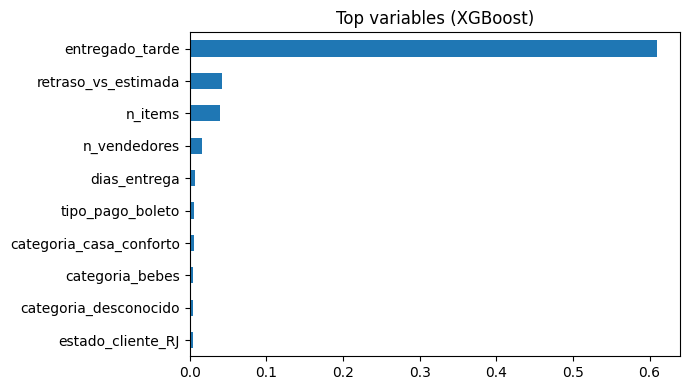

entregado_tarde            0.609
retraso_vs_estimada        0.042
n_items                    0.040
n_vendedores               0.016
dias_entrega               0.006
tipo_pago_boleto           0.006
categoria_casa_conforto    0.005
categoria_bebes            0.005
categoria_desconocido      0.004
estado_cliente_RJ          0.004


In [11]:
# --- Importancia de variables del modelo elegido ---
modelo_mejor = xgb if mejor == "XGBoost" else logreg
if mejor == "XGBoost":
    oh = modelo_mejor.named_steps["prep"].named_transformers_["cat"].named_steps["oh"]
    nombres = NUMERICAS + list(oh.get_feature_names_out(CATEGORICAS))
    imp = pd.Series(modelo_mejor.named_steps["clf"].feature_importances_, index=nombres)
    top = imp.sort_values(ascending=False).head(10)
    top.sort_values().plot.barh(figsize=(7, 4), title="Top variables (XGBoost)"); plt.tight_layout(); plt.show()
    print(top.round(3).to_string())

### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

In [12]:
import joblib, json

final = xgb if mejor == "XGBoost" else logreg
final.fit(pedidos[X_cols], y)                       # modelo final: TODOS los pedidos
proba_all = final.predict_proba(pedidos[X_cols])[:, 1]
umbral = float(np.quantile(proba_all, 0.90))        # umbral del 10% de mayor riesgo
joblib.dump(final, "modelo_riesgo.joblib")
json.dump({"umbral": umbral}, open("umbral.json", "w"))
print("Modelo guardado. Umbral del 10%:", round(umbral, 4))

Modelo guardado. Umbral del 10%: 0.2693


In [13]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]

array([0.05587885, 0.09271377, 0.0496444 , 0.12309952, 0.05273617],
      dtype=float32)

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. **¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?**
   En validación (marzo–mayo 2018, 20,422 pedidos) el XGBoost logra una precisión en el 10% de **0.663**, contra **0.621** de la regla del retraso (**×1.07**) y **0.146** del azar (**×4.53**). La regresión logística queda en **0.613**, por debajo de la regla. El XGBoost le gana a la regla **por poco**, porque esa regla ya es muy buena: el retraso es el principal detonante de una mala reseña.
2. **¿Qué tres variables pesan más y por qué tiene sentido para el negocio?**
   `entregado_tarde` (0.609 de la importancia), `retraso_vs_estimada` (0.042) y `n_items` (0.040). Un pedido que llega después de la fecha prometida frustra al cliente, y cuanto más tarde llega, peor; los pedidos con más artículos tienen más cosas que pueden salir mal (envíos parciales, un artículo que falta).
3. **¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?**
   Perdería su señal principal: más del 60% de la importancia está en `entregado_tarde`. Si casi nadie llega tarde, esa variable vale 0 para todos y el 10% marcado se parecería más al azar (0.146). Habría que apoyarse en las demás variables (artículos, categoría, geografía, pago), medir de nuevo la precisión y recalcular el umbral.


## Parte 3 · Pregunta abierta

Opción elegida: **3B · Segmentación de vendedores**

Elegimos 3B porque es autocontenida (no depende de los datos ocultos de junio) y da una lectura comercial accionable: agrupar a los vendedores por **cómo operan** para diseñar una estrategia por segmento.

In [14]:
# Una fila por vendedor con >= 10 pedidos entregados (variables definidas con SQL)
query_vendedores = '''
WITH por_pedido AS (
    SELECT oi.seller_id, o.order_id,
           SUM(oi.price)         AS precio,
           SUM(oi.freight_value) AS flete,
           MAX(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                    THEN 1 ELSE 0 END) AS tarde,
           (MAX(o.order_delivered_customer_date)::date
            - MAX(o.order_purchase_timestamp)::date) AS dias_entrega
    FROM final.order_items oi
    JOIN final.orders o ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY oi.seller_id, o.order_id
),
cats AS (
    SELECT oi.seller_id, COUNT(DISTINCT p.product_category_name) AS n_categorias
    FROM final.order_items oi
    JOIN final.orders o ON o.order_id = oi.order_id AND o.order_status = 'delivered'
    LEFT JOIN final.products p ON p.product_id = oi.product_id
    GROUP BY oi.seller_id
)
SELECT pp.seller_id, s.seller_state,
       COUNT(*)                                 AS pedidos,
       SUM(pp.precio)                           AS ventas,
       SUM(pp.flete)                            AS flete_total,
       SUM(pp.flete) / NULLIF(SUM(pp.precio),0) AS flete_relativo,
       SUM(pp.precio) / COUNT(*)                AS ticket_medio,
       AVG(pp.tarde::numeric)                   AS tasa_retraso,
       AVG(pp.dias_entrega)                     AS dias_entrega_prom,
       c.n_categorias
FROM por_pedido pp
JOIN final.sellers s ON s.seller_id = pp.seller_id
JOIN cats c          ON c.seller_id = pp.seller_id
GROUP BY pp.seller_id, s.seller_state, c.n_categorias
HAVING COUNT(*) >= 10
ORDER BY ventas DESC
'''
with motor.connect() as conn:
    vendedores = pd.read_sql_query(text(query_vendedores), con=conn)
print("Vendedores con >=10 pedidos:", len(vendedores))
vendedores.head()

Vendedores con >=10 pedidos: 1005


,seller_id,seller_state,pedidos,ventas,flete_total,flete_relativo,ticket_medio,tasa_retraso,dias_entrega_prom,n_categorias
0,53243585a1d6dc2643021fd1853d8905,BA,262,192353.24,9527.59,0.049532,734.172672,0.034351,13.854962,2
1,4869f7a5dfa277a7dca6462dcf3b52b2,SP,894,188509.13,15587.74,0.082690,210.860324,0.140940,16.549217,7
2,4a3ca9315b744ce9f8e9374361493884,SP,1572,177432.72,29846.25,0.168212,112.870687,0.119593,15.144402,7
3,7c67e1448b00f6e969d365cea6b010ab,SP,896,172317.99,46976.65,0.272616,192.319185,0.101562,22.314732,6
4,7e93a43ef30c4f03f38b393420bc753a,SP,317,165563.49,5955.13,0.035969,522.282303,0.053628,11.205047,7


  File "c:\Users\Javier Andino\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Javier Andino\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Javier Andino\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process

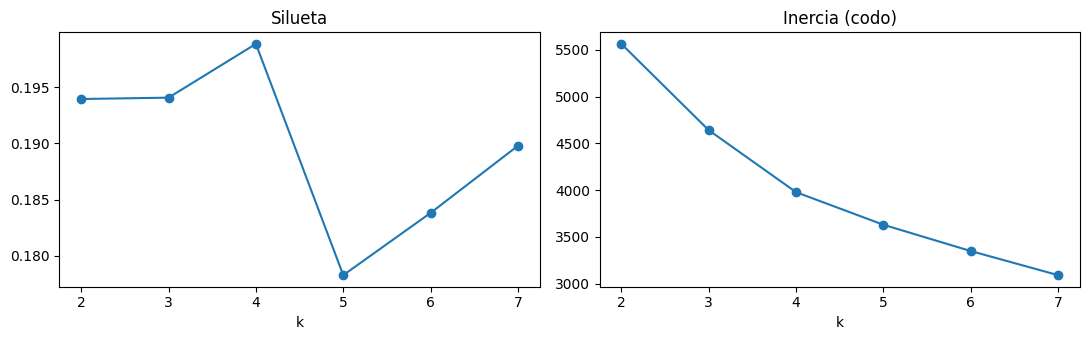

 k  silueta  inercia
 2    0.194 5562.226
 3    0.194 4640.339
 4    0.199 3978.188
 5    0.178 3629.910
 6    0.184 3349.116
 7    0.190 3091.635


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

LOG = ["pedidos", "ventas", "ticket_medio", "n_categorias"]   # colas largas -> log1p
LINEAL = ["flete_relativo", "tasa_retraso", "dias_entrega_prom"]
FEATS = LOG + LINEAL

X = vendedores[FEATS].copy()
for c in LOG:
    X[c] = np.log1p(X[c])
Xs = StandardScaler().fit_transform(X)

filas = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    filas.append({"k": k, "silueta": silhouette_score(Xs, km.labels_), "inercia": km.inertia_})
sil = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(sil["k"], sil["silueta"], "o-"); ax[0].set_title("Silueta"); ax[0].set_xlabel("k")
ax[1].plot(sil["k"], sil["inercia"], "o-"); ax[1].set_title("Inercia (codo)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(sil.round(3).to_string(index=False))

In [16]:
# k = 4: mayor silueta y cuatro grupos interpretables (la métrica y el negocio coinciden)
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
vendedores["grupo"] = km.labels_

pca = PCA(n_components=2, random_state=42).fit(Xs)
comp = pca.transform(Xs)
vendedores["pca1"], vendedores["pca2"] = comp[:, 0], comp[:, 1]
print(f"PCA: los 2 componentes conservan {pca.explained_variance_ratio_.sum()*100:.0f}% de la variación")

# Nombrar por perfil (no por número: K-Means numera al azar)
perfil = vendedores.groupby("grupo")[FEATS].median()
g_grande  = perfil["pedidos"].idxmax()
g_lento   = perfil.drop(index=g_grande)["tasa_retraso"].idxmax()
resto     = perfil.drop(index=[g_grande, g_lento])
g_flete   = resto["flete_relativo"].idxmax()
g_premium = resto.drop(index=g_flete)["ticket_medio"].idxmax()
nombres = {g_grande: "Grandes multicategoría", g_lento: "Entrega lenta / alto retraso",
           g_flete: "Bajo ticket / flete alto", g_premium: "Nicho premium confiable"}
vendedores["nombre_grupo"] = vendedores["grupo"].map(nombres)
vendedores.to_csv("vendedores_segmentados.csv", index=False)
vendedores["nombre_grupo"].value_counts()

PCA: los 2 componentes conservan 60% de la variación


nombre_grupo
Nicho premium confiable         354
Bajo ticket / flete alto        252
Grandes multicategoría          244
Entrega lenta / alto retraso    155
Name: count, dtype: int64

In [17]:
# Perfil (mediana) por segmento
vendedores.groupby("nombre_grupo")[FEATS].median().round(2)

,pedidos,ventas,ticket_medio,n_categorias,flete_relativo,tasa_retraso,dias_entrega_prom
nombre_grupo,,,,,,,
Bajo ticket / flete alto,22.0,1272.96,53.77,2.0,0.35,0.06,11.91
Entrega lenta / alto retraso,21.0,3424.18,131.89,2.0,0.19,0.18,17.52
Grandes multicategoría,122.5,11959.50,103.08,5.0,0.21,0.07,13.08
Nicho premium confiable,24.0,4107.50,160.07,2.0,0.14,0.05,12.20


In [18]:
# ¿Qué segmento concentra las malas reseñas? (solo para describir los grupos; NO entra al K-Means)
query_mala = '''
WITH resena AS (
    SELECT DISTINCT ON (order_id) order_id, (review_score <= 2)::int AS mala_resena
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC
)
SELECT DISTINCT oi.seller_id, oi.order_id, r.mala_resena
FROM final.order_items oi
JOIN final.orders o ON o.order_id = oi.order_id
JOIN resena r       ON r.order_id = oi.order_id
WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
'''
with motor.connect() as conn:
    mala_vend = pd.read_sql_query(text(query_mala), con=conn)
mala_seg = (mala_vend.merge(vendedores[["seller_id", "nombre_grupo"]], on="seller_id")
                     .groupby("nombre_grupo")["mala_resena"].agg(["mean", "size"])
                     .rename(columns={"mean": "tasa_mala_resena", "size": "pedidos"})
                     .sort_values("tasa_mala_resena", ascending=False))
mala_seg.round(3)


,tasa_mala_resena,pedidos
nombre_grupo,,
Entrega lenta / alto retraso,0.234,4892
Grandes multicategoría,0.139,49810
Bajo ticket / flete alto,0.124,8466
Nicho premium confiable,0.110,10306


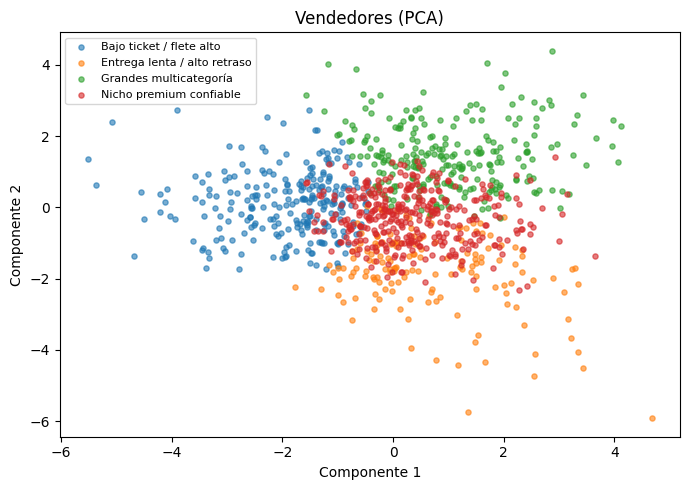

In [19]:
# Mapa de los grupos con PCA
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5))
for g, sub in vendedores.groupby("nombre_grupo"):
    ax.scatter(sub["pca1"], sub["pca2"], s=14, alpha=.6, label=g)
ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2"); ax.legend(fontsize=8); ax.set_title("Vendedores (PCA)")
plt.tight_layout(); plt.show()

**Lectura de los segmentos y acción para cada uno:**

- **Grandes multicategoría** — mucho volumen y catálogo amplio, buen servicio. *Acción:* cuentas clave; soporte prioritario y tarifas de logística por volumen.
- **Entrega lenta / alto retraso** — la peor tasa de retraso (mediana 18%) y la entrega más larga (17.5 días). *Acción:* plan de mejora de SLA (alertas de despacho, revisar transportistas). **Es el segmento con más malas reseñas: 23.4% de sus pedidos, contra 11–14% de los demás** (tabla de arriba) → conecta con la Parte 2.
- **Bajo ticket / flete alto** — ventas bajas y flete caro respecto al precio. *Acción:* renegociar/subsidiar flete, promover envío combinado o gratis desde un monto.
- **Nicho premium confiable** — ticket alto, poco retraso, entrega rápida. *Acción:* fidelizar y usarlos como referencia de servicio; ampliar su catálogo.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasificamos una muestra de comentarios con un modelo preentrenado de Hugging Face que entiende portugués (`cardiffnlp/twitter-xlm-roberta-base-sentiment`) y lo comparamos con las estrellas. **Activen la GPU de Colab.**

Importante: estos comentarios se usan como **tema de análisis**, NO como variable del modelo de riesgo (ahí siguen prohibidos: son información posterior a la entrega).

In [20]:
!pip install -q transformers torch

In [21]:
from transformers import pipeline
import torch

# Muestra de >= 1,000 comentarios con texto (semilla fija)
comentarios = pd.read_sql('''
    SELECT review_score, review_comment_message
    FROM final.order_reviews
    WHERE review_comment_message IS NOT NULL AND length(trim(review_comment_message)) > 0
    ORDER BY review_id, order_id
''', motor)
muestra = comentarios.sample(1200, random_state=42).reset_index(drop=True)

dev = 0 if torch.cuda.is_available() else -1
clasificador = pipeline("sentiment-analysis",
                        model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                        device=dev, truncation=True)
pred = clasificador(muestra["review_comment_message"].tolist(), batch_size=32)
muestra["sentimiento"] = [p["label"] for p in pred]       # positive / neutral / negative
muestra.head()

Device set to use cpu
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


,review_score,review_comment_message,sentimiento
0,5,Recomendo,positive
1,5,eu recomendo otimo trabalho e produto\r\nbom ....,positive
2,1,"Produto nao entregue, enviado um dos itens da ...",negative
3,1,Meu produto só chegou o shampoo o condicionado...,negative
4,5,muito bom,positive


In [22]:
# Estrellas agrupadas como el modelo: 1-2 negativo, 3 neutro, 4-5 positivo
def estrellas_lbl(s):
    return "negative" if s <= 2 else ("neutral" if s == 3 else "positive")
muestra["estrellas_lbl"] = muestra["review_score"].map(estrellas_lbl)

tabla = pd.crosstab(muestra["estrellas_lbl"], muestra["sentimiento"])
coincidencia = (muestra["estrellas_lbl"] == muestra["sentimiento"]).mean()
print("Coincidencia sentimiento vs estrellas:", round(coincidencia * 100, 1), "%")
tabla

Coincidencia sentimiento vs estrellas: 68.8 %


sentimiento,negative,neutral,positive
estrellas_lbl,,,
negative,217,134,7
neutral,43,36,21
positive,38,132,572


In [30]:
# Coincidencia por grupo de estrellas: dónde acierta y dónde se confunde el modelo
orden = ["negative", "neutral", "positive"]
por_grupo = (tabla.reindex(index=orden, columns=orden, fill_value=0)
                  .assign(total=lambda t: t.sum(axis=1)))
por_grupo["coinciden"] = [por_grupo.loc[g, g] for g in orden]
por_grupo["pct_coincidencia"] = (por_grupo["coinciden"] / por_grupo["total"] * 100).round(1)
por_grupo["pct_leido_neutral"] = (por_grupo["neutral"] / por_grupo["total"] * 100).round(1)
print("Coincidencia total:", round(por_grupo["coinciden"].sum() / por_grupo["total"].sum() * 100, 1), "%")
por_grupo

Coincidencia total: 68.8 %


sentimiento,negative,neutral,positive,total,coinciden,pct_coincidencia,pct_leido_neutral
estrellas_lbl,,,,,,,
negative,217,134,7,358,217,60.6,37.4
neutral,43,36,21,100,36,36.0,36.0
positive,38,132,572,742,572,77.1,17.8


In [23]:
# Al menos 5 desacuerdos
desacuerdos = muestra[muestra["estrellas_lbl"] != muestra["sentimiento"]]
muestra.to_csv("sentimiento_muestra.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(desacuerdos.head(10)[["review_score", "estrellas_lbl", "sentimiento", "review_comment_message"]])

,review_score,estrellas_lbl,sentimiento,review_comment_message
8,3,neutral,negative,Mas o produto não fez efeito nenhum
10,4,positive,neutral,"O produto funciona bem, é um pouco duro os botões , demorou a entrega por ser final de ano, mas já comprei outros produtos e a entrega é qualidade são bons."
13,5,positive,neutral,Produto conforme solicitado.
16,1,negative,neutral,Faltou outro kit ja que comprei 2
19,2,negative,positive,"Comprei outros produtos e sempre vieram, só estou tendo problema com este, mais no geral é um site muito bom de se comprar."
22,4,positive,neutral,O Produto chegou
23,3,neutral,negative,Um dos itens do kit está incorreto.
27,4,positive,neutral,Tudo conforme anúncio. Só achei um pouco fina a malha.
28,1,negative,neutral,"A previsão para entrega seria para até 12/12/17, e até o momento não foi entregue!"
31,1,negative,neutral,Era para receber o produto até 19/3 e age hoje (23/3) não recebi e não sei o motivo


In [31]:
# Los 5 desacuerdos leídos y clasificados (índices de la tabla anterior; la muestra es reproducible)
clasificacion = {
    8:  ("cliente", "Queja clara ('não fez efeito nenhum') con 3 estrellas: la nota es más generosa que el texto."),
    13: ("modelo",  "Satisfecho pero descriptivo ('conforme solicitado'): sin palabras de emoción, el modelo dice neutral."),
    16: ("modelo",  "Queja por un artículo faltante sin palabras negativas: el modelo no ve el problema."),
    19: ("modelo",  "Texto mixto: elogia el sitio pero se queja de este pedido; el modelo se queda con el elogio."),
    28: ("modelo",  "Pedido no entregado contado con fechas: queja de hecho, el modelo la lee como neutral."),
}
leidos = desacuerdos.loc[list(clasificacion), ["review_score", "estrellas_lbl", "sentimiento", "review_comment_message"]].copy()
leidos["quien_se_equivoco"] = [clasificacion[i][0] for i in leidos.index]
leidos["por_que"] = [clasificacion[i][1] for i in leidos.index]
print(leidos["quien_se_equivoco"].value_counts().to_string())
with pd.option_context("display.max_colwidth", None):
    display(leidos)

quien_se_equivoco
modelo     4
cliente    1


,review_score,estrellas_lbl,sentimiento,review_comment_message,quien_se_equivoco,por_que
8,3,neutral,negative,Mas o produto não fez efeito nenhum,cliente,Queja clara ('não fez efeito nenhum') con 3 estrellas: la nota es más generosa que el texto.
13,5,positive,neutral,Produto conforme solicitado.,modelo,"Satisfecho pero descriptivo ('conforme solicitado'): sin palabras de emoción, el modelo dice neutral."
16,1,negative,neutral,Faltou outro kit ja que comprei 2,modelo,Queja por un artículo faltante sin palabras negativas: el modelo no ve el problema.
19,2,negative,positive,"Comprei outros produtos e sempre vieram, só estou tendo problema com este, mais no geral é um site muito bom de se comprar.",modelo,Texto mixto: elogia el sitio pero se queja de este pedido; el modelo se queda con el elogio.
28,1,negative,neutral,"A previsão para entrega seria para até 12/12/17, e até o momento não foi entregue!",modelo,"Pedido no entregado contado con fechas: queja de hecho, el modelo la lee como neutral."


### Preguntas

1. **¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?**
   Coinciden en el **68.8%** de los 1,200 comentarios. Por grupo (tabla de coincidencia por grupo): 572 de 742 positivos (77.1%), 217 de 358 negativos (60.6%) y solo 36 de 100 neutros (36.0%). La mayor confusión es que el modelo lee como **neutral** textos que tienen 1–2 estrellas (134) o 4–5 estrellas (132): son comentarios que describen un hecho ("o produto chegou", "faltou um kit") sin palabras de emoción.
2. **5 desacuerdos — ¿error del modelo o del cliente?** (tabla `leidos` de arriba: 4 errores del modelo y 1 del cliente)
   - **Fila 8 · 3★, modelo negativo** — *"Mas o produto não fez efeito nenhum"*: el texto es una queja clara. **Error del cliente:** la nota es más generosa que lo que escribe.
   - **Fila 13 · 5★, modelo neutral** — *"Produto conforme solicitado."*: el cliente está satisfecho pero lo dice de forma descriptiva. **Error del modelo:** texto corto sin palabras de emoción.
   - **Fila 16 · 1★, modelo neutral** — *"Faltou outro kit ja que comprei 2"*: es una queja (le faltó un artículo). **Error del modelo:** no reconoce el problema porque no hay palabras negativas.
   - **Fila 19 · 2★, modelo positivo** — *"…só estou tendo problema com este, mais no geral é um site muito bom"*: texto mixto. **Error del modelo:** se queda con el elogio al sitio, pero la nota es sobre este pedido.
   - **Fila 28 · 1★, modelo neutral** — *"A previsão para entrega seria para até 12/12/17, e até o momento não foi entregue!"*: queja por un pedido que no llega, contada con fechas. **Error del modelo.**
   En resumen, la mayoría de los desacuerdos son del modelo: quejas contadas como hechos (fechas, piezas que faltan) que no suenan negativas.
3. **¿Qué dice el texto que las estrellas no dicen?** El **motivo**: retraso o pedido no entregado, piezas que faltan, producto distinto al anunciado, calidad. A Olist le sirve para clasificar las quejas por causa y mandarlas al área correcta (logística, vendedor, catálogo), y para detectar clientes que ponen buena nota pero se quejan.


## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Mostramos la curva de pérdida con *early stopping* y comparamos con el XGBoost.

In [24]:
!pip install -q tensorflow

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
googleapis-common-protos 1.66.0 requires protobuf!=3.20.0,!=3.20.1,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0.dev0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-api-core 2.24.0 requires protobuf!=3.20.0,!=3.20.1,!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0.dev0,>=3.19.5, but you have protobuf 7.36.2 which is incompatible.
proto-plus 1.25.0 requires protobuf<6.0.0dev,>=3.19.0, but you have protobuf 7.36.2 which is incompatible.


In [25]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipe

# Preprocesador que devuelve una matriz DENSA (lo que necesita Keras)
prep_nn = ColumnTransformer([
    ("num", SkPipe([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUMERICAS),
    ("cat", SkPipe([("imp", SimpleImputer(strategy="constant", fill_value="desconocido")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False))]), CATEGORICAS),
])
Xtr = prep_nn.fit_transform(crear_variables(pedidos.loc[tr, X_cols]))
Xva = prep_nn.transform(crear_variables(pedidos.loc[va, X_cols]))
ytr, yva = y[tr].to_numpy(), y[va].to_numpy()

tf.keras.utils.set_random_seed(42)
red = keras.Sequential([
    keras.layers.Input(shape=(Xtr.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
red.compile(optimizer="adam", loss="binary_crossentropy", metrics=["AUC"])
peso = {0: 1.0, 1: float((ytr == 0).sum() / (ytr == 1).sum())}   # clases desbalanceadas
parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = red.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=50, batch_size=256,
               class_weight=peso, callbacks=[parar], verbose=0)
print("Épocas entrenadas:", len(hist.history["loss"]))

Épocas entrenadas: 18


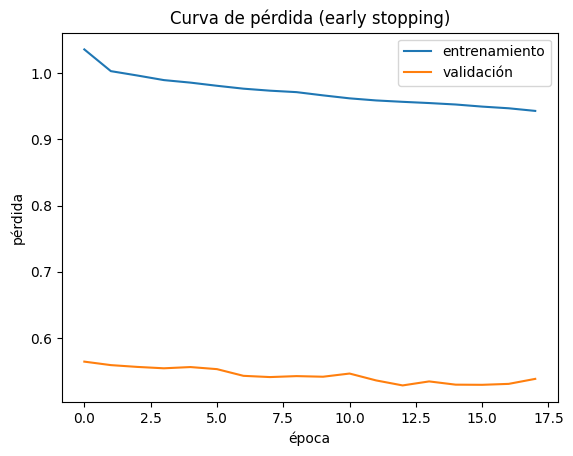

Red neuronal  precisión@10% = 0.659
XGBoost       precisión@10% = 0.663


In [26]:
plt.plot(hist.history["loss"], label="entrenamiento")
plt.plot(hist.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.legend(); plt.title("Curva de pérdida (early stopping)"); plt.show()

score_nn = red.predict(Xva, verbose=0).ravel()
print(f"Red neuronal  precisión@10% = {precision_en_10(yva, score_nn):.3f}")
print(f"XGBoost       precisión@10% = {resultados['XGBoost']:.3f}")

**Resultado:** con la misma división por fecha, la red densa se detuvo sola en la época 18 (*early stopping*) y logró una precisión en el 10% de **0.659**, contra **0.663** del XGBoost: prácticamente un empate, con ventaja mínima para el XGBoost. En datos de tabla con pocas variables, mezcla de numéricas y categóricas, y una señal dominante tipo umbral (`entregado_tarde`), los árboles de gradient boosting capturan esas reglas directamente, sin escalar ni ajustar tantos hiperparámetros, y entrenan mucho más rápido. La red necesitaría más datos o variables más ricas para sacar ventaja.


## Parte 5 · Despliegue

- URL de la API en Render: **https://olist-bs8i.onrender.com**
- URL de la app de Streamlit: **https://avgbsjf2bba9umpopq65m4.streamlit.app**

Versiones de este entorno (cópienlas al `requirements.txt` de la API):

In [27]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):

In [29]:
import requests
URL_API = "https://olist-bs8i.onrender.com"   # la primera llamada puede tardar ~1 min si Render la durmió
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'probabilidad': 0.0559, 'riesgo_alto': False, 'umbral': 0.2693}

## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, el enlace o una copia.

**Ficha:** [`ficha_modelo.md`](ficha_modelo.md) · en la app: https://avgbsjf2bba9umpopq65m4.streamlit.app/ficha